In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

In [4]:
T = 24 # Time periods
nb = 5 # Buses
nl = 4 # Lines
ng = 3 # Generators

In [5]:
# Generator-to-bus mapping
G = np.array([
    [1, 0, 0],
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [0, 0, 0]
])

# Line-to-bus mapping
K = np.array([
    [1, -1, 0, 0, 0],
    [1, 0, -1, 0, 0],
    [0, 0, 1, -1, 0],
    [0, 0, 0, 1, -1]
]).T

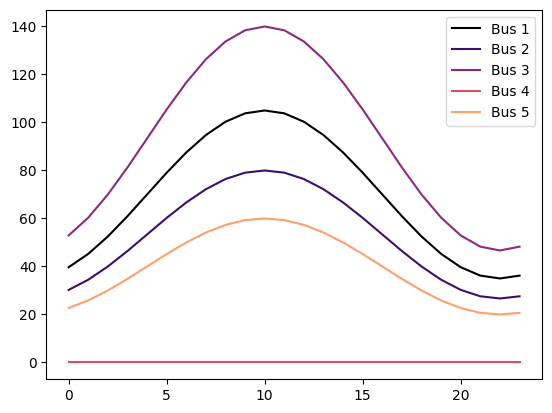

Total Peak Demand: 385 MW
Total Generation Capacity: 320 MW
Total Transmission Capacity: 325 MW


In [60]:
# Time
time = np.arange(24)

# Load
load_shape =  (np.sin(2 * np.pi * time / T - np.pi / 3) + 2) / 3
peak_demand = np.array([105, 80, 140, 0, 60])
load = (peak_demand * load_shape.reshape(-1, 1)).T

# Plot load shapes
cmap = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [cmap(i/5) for i in range(nb)]
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.show()

# Print total peak demand
print(f"Total Peak Demand: {peak_demand.sum()} MW")

# Generation
pmax = np.array([150, 95, 75])
print(f"Total Generation Capacity: {pmax.sum()} MW")

# Lines
fmax = np.array([100, 50, 100, 75])
print(f"Total Transmission Capacity: {fmax.sum()} MW")

# VoLL Dynamics
epsilon = 0.5
alpha = 0.5
beta = 2

# Reshape data
pmax = np.tile(pmax[:, None], (1, T))
fmax = np.tile(fmax[:, None], (1, T))

In [61]:
# CVXPY Model

# Variables
p = cp.Variable((ng, T), nonneg=True)
f = cp.Variable((nl, T))
u = cp.Variable((nb, T), nonneg=True)
z = cp.Variable((nb, T), nonneg=True)

# Parameters
eps = cp.Parameter((nb, T), nonneg=True) # Static Slope
eps.value = epsilon * np.ones((nb, T))
x = cp.Parameter((nb, T+1), nonneg=True) # Dynamic Slope / State
x.value = np.zeros((nb, T+1))
lam = cp.Parameter((nb, T+1), nonneg=True) # Costate
lam.value = np.zeros((nb, T+1))
d = cp.Parameter((nb, T), nonneg=True) # Demand
d.value = load

# Objectives
ue_costs = 0.5 * cp.sum(cp.multiply(eps + x[:,:-1], cp.square(u))) # Minimize unserved energy costs with static state variable
hamiltonian = ue_costs + beta * cp.sum(cp.multiply(lam[:,1:], z)) # Minimize Hamiltonian

# Constraints
constraints = [
    G @ p + K @ f == d - u,
    p <= pmax,
    f <= fmax,
    f >= -fmax,
    u == cp.multiply(d, z),
    z <= 1,
]

# Problem
problem = cp.Problem(cp.Minimize(hamiltonian), constraints)

# Solve
result = problem.solve("GUROBI")

print(result)
print(H_eval())
print(J_eval(z.value))

1103.216954715724
1103.216954715724
2156.769799311584


In [62]:
def x_eval(z):
    # State trajectory eval
    x = np.zeros((nb, T+1))
    for t in range(T):
        x[:, t+1] = alpha * x[:,t] + beta * z[:, t]
    return x

def lam_eval(z):
    # Costate trajectory eval
    lam = np.zeros((nb, T + 1))
    u = d.value * z
    for t in range(T)[::-1]:
        lam[:, t] = 0.5 * np.square(u[:, t]) + alpha * lam[:, t + 1]
    return lam

def H_eval():
    # Hamiltonian eval
    # Call this after updating lam and x parameters
    return (hamiltonian + alpha * cp.sum(cp.multiply(lam[:, 1:], x[:, :-1]))).value

def J_eval(z):
    # Objective eval
    x = x_eval(z)
    u = d.value * z
    return 0.5 * np.sum(np.multiply(eps.value + x[:,:-1], np.square(u)))

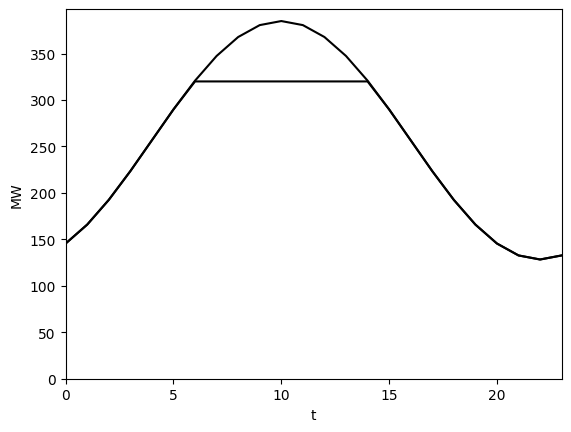

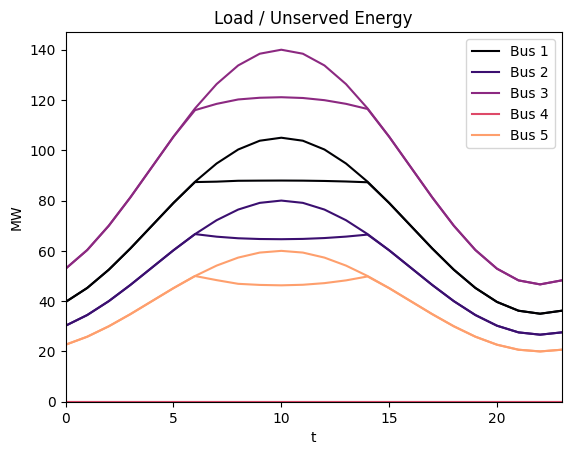

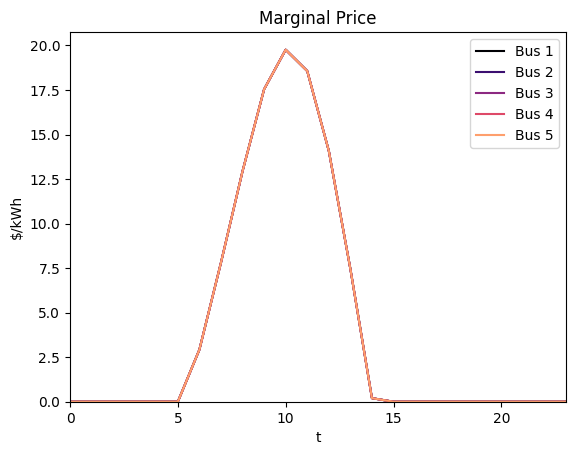

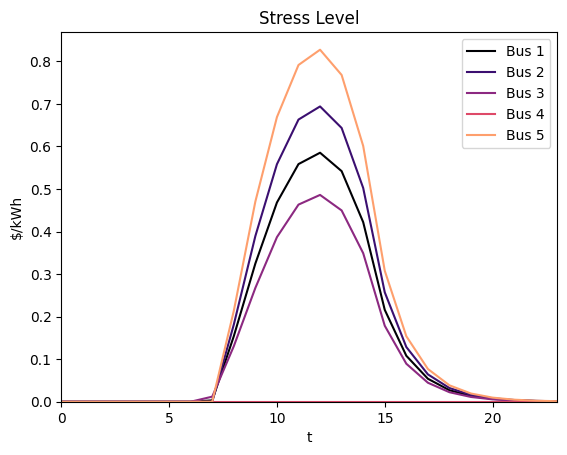

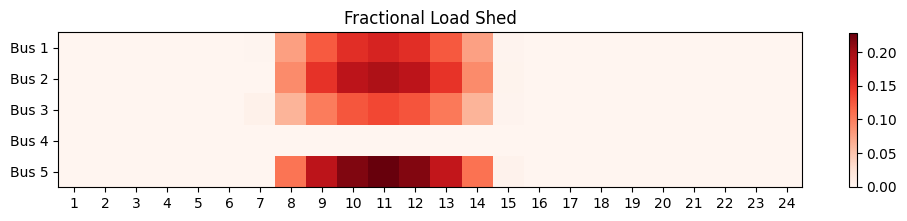

In [67]:
magma = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [magma(i/5) for i in range(nb)]

# Plot total unserved energy
plt.plot(time, np.sum(load, axis=0), color="black", label="Total")
plt.plot(time, np.sum(load - u.value, axis=0), color="black")
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot unserved energy by bus
plt.title("Load / Unserved Energy")
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
    plt.plot(time, load[i,:] - u[i, :].value, color=colors[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot risk by bus
lmp = -constraints[0].dual_value
plt.title("Marginal Price")
for i in range(nb):
    plt.plot(time, lmp[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot stress level by bus
xval = x_eval(z.value)
plt.title("Stress Level")
for i in range(nb):
    plt.plot(time, xval[i,:-1], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot load shed fractions by bus
reds = plt.colormaps["Reds"]
plt.figure(figsize=(12, 10))
plt.title("Fractional Load Shed")
img = plt.imshow(z.value, cmap=reds)
plt.xticks(np.arange(T), [f"{t+1}" for t in np.arange(T)])
plt.yticks(np.arange(nb), [f"Bus {i+1}" for i in np.arange(nb)])
plt.colorbar(img, shrink=0.2)
plt.show()

In [68]:
print(u.value.sum(axis=1))

[88.46058489 80.08619524 98.00998306  0.         71.80231167]


In [65]:
from scipy.optimize import minimize_scalar

def exact_line_search(z_k, z_star):

    direction = z_star - z_k
    result = minimize_scalar(
        lambda a: J_eval(z_k + a * direction),
        bounds=(0, 1),
        method="bounded"
    )

    candidates = [0.0, result.x, 1.0]
    return min(candidates, key=lambda a: J_eval(z_k + a * direction))

In [69]:
# MSA Loop

# Solve model to initialize z_hat
z_hat = z.value

for k in range(10):

    # Update state trajectory
    x.value = x_eval(z_hat)
    
    # Update costate trajectory
    lam.value = lam_eval(z_hat)

    # Evaluate Hamiltonian
    print(H_eval(), J_eval(z_hat))

    # Solve model with Hamiltonian objective
    result = problem.solve("GUROBI")

    # Update z_hat
    a = exact_line_search(z_hat, z.value)
    z_hat = (1 - a) * z_hat + a * z.value

3593.989556210355 2101.496422432583
3593.9902996613523 2101.4964223586812
3593.990044388057 2101.496422334937
3593.9902738737164 2101.496422325634
3593.99007137164 2101.4964223206366
3593.9901951434094 2101.4964223179395
3593.9900859036215 2101.4964223164807
3593.9901531231726 2101.496422315689
3593.990093864957 2101.4964223152615
3593.9901299154617 2101.4964223150296
